# Entrega 2 — Data Science
Bruno Henrique e Luiz Henrique · 24/10/2026

Tema: homicídios de mulheres nas cinco grandes regiões do Brasil, de 2000 a 2023.


| Etapas | Responsável proposto |
|---|---|
| Escolha da base, governança, carga, dicionário e análise exploratória | Bruno Henrique |
| Qualidade, tratamento, plano de modelagem e avaliação | Luiz Henrique |

O estudo é descritivo. Não há modelo treinado nem integração com o aplicativo.


## 0. Bibliotecas
Execute as células de cima para baixo, com a pasta `dados/` ao lado do notebook.
As bibliotecas estão em `requirements.txt`. O código usa os dados locais, sem baixar novas versões.


In [1]:
from pathlib import Path
import json, hashlib, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

BASE = Path.cwd()
if not (BASE / 'dados' / 'brutos').exists() and (BASE / 'data-science' / 'dados').exists():
    BASE = BASE / 'data-science'
assert (BASE / 'dados' / 'brutos').exists(), 'Abra a pasta data-science antes de executar.'
DADOS = BASE / 'dados'
BRUTOS = DADOS / 'brutos'
ANO_INICIO, ANO_FIM = 2000, 2023
COR, COR2 = '#157F83', '#E08B42'
pd.set_option('display.max_columns', 20)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .2})


def grafico(nome, leitura):
    plt.tight_layout()
    plt.show()
    display(Markdown('**Leitura:** ' + leitura))

print('Integrantes: Bruno Henrique e Luiz Henrique')
print('Recorte:', ANO_INICIO, 'a', ANO_FIM)
print('Versões: pandas', pd.__version__, '| numpy', np.__version__)


Integrantes: Bruno Henrique e Luiz Henrique
Recorte: 2000 a 2023
Versões: pandas 3.0.1 | numpy 2.3.5


## 1. Escolha da base e governança
**Responsável Bruno Henrique** 

Escolhemos o Atlas da Violência porque é uma das fontes sugeridas, contém dados públicos e permite estudar a evolução e as diferenças regionais da violência letal contra mulheres. Para o aplicativo, os resultados podem ajudar a contextualizar conteúdos informativos. A base não serve para prever o risco de uma pessoa.

| Informação | Descrição |
|---|---|
| Nome | Atlas da Violência — Homicídios de mulheres |
| Fonte | [Portal do Atlas](https://www.ipea.gov.br/atlasviolencia/) |
| Órgãos responsáveis | Ipea e Fórum Brasileiro de Segurança Pública; origem dos registros: SIM/Ministério da Saúde |
| Indicadores | [Série 40: quantidade](https://www.ipea.gov.br/atlasviolencia/dados-series/40/) e [série 52: taxa](https://www.ipea.gov.br/atlasviolencia/dados-series/52/) |
| Acesso | 24/10/2026 |
| Granularidade | Uma região em um ano, não uma vítima |
| Abrangência | Norte, Nordeste, Sudeste, Sul e Centro-Oeste |
| Período utilizado | Contagens de 2000 a 2023; taxas de 2000 a 2022 |
| Termos de uso | O Atlas 2025 permite reprodução com citação e proíbe uso comercial. A API JSON não informa licença específica; esse ponto continua pendente de confirmação para redistribuição pública |
| Privacidade / LGPD | Não há nomes, documentos ou registros individuais de vítimas. Não houve coleta própria de dados pessoais |
| Risco de reidentificação | Baixo neste recorte de grandes regiões e anos. Não cruzar dados para tentar identificar pessoas |
| Limitações | Sub-registro, possíveis erros na classificação das mortes, revisões dos dados, defasagem entre séries e diferenças internas escondidas pela agregação |

Os termos e a metodologia da publicação podem ser consultados no [Atlas da Violência 2025](https://www.ipea.gov.br/atlasviolencia/arquivos/artigos/5999-atlasdaviolencia2025.pdf). A permissão da publicação não é apresentada como uma licença específica da API. Não atribuímos licença Creative Commons sem confirmação.

Homicídios de mulheres não equivalem necessariamente a feminicídios. Esta base também não mede violência não letal ou repetição da violência. Os resultados descrevem as séries baixadas, não a edição mais recente de todas as publicações do Atlas.

**Aviso:** protótipo acadêmico. Os indicadores não substituem atendimento policial, jurídico, psicológico ou de saúde.


## 2. Carga e dicionário de dados
**Responsável Bruno Henrique**

Os arquivos em `dados/brutos/` foram preservados sem alteração. O manifesto registra os links e hashes dos arquivos. Brasil e regiões ficam separados para não contar os mesmos óbitos duas vezes.


In [2]:
manifesto = json.loads((DADOS / 'manifesto_fontes.json').read_text(encoding='utf-8'))
for m in manifesto:
    assert hashlib.sha256((BRUTOS / m['arquivo']).read_bytes()).hexdigest() == m['sha256']
print('Integridade: todos os arquivos brutos coincidem com os hashes de aquisição.')

def ler(nome):
    return pd.DataFrame(json.loads((BRUTOS / nome).read_text(encoding='utf-8')))

cont = ler('homicidios_regioes.json')
taxas = ler('taxas_regioes.json')
nacional = ler('homicidios_brasil.json')
taxa_nacional = ler('taxas_brasil.json')
geo = json.loads((BRUTOS / 'regioes_referencia.geojson').read_text(encoding='utf-8'))
ref = pd.DataFrame([{'regiao_id': int(f['properties']['code']),
                     'regiao': f['properties']['name']} for f in geo['features']])
display(pd.DataFrame([
    (n, len(t), t['periodo'].min(), t['periodo'].max(), int(t.isna().sum().sum()))
    for n, t in [('contagem regional', cont), ('taxa regional', taxas),
                 ('contagem Brasil', nacional), ('taxa Brasil', taxa_nacional)]
], columns=['fonte', 'linhas', 'primeiro período', 'último período', 'nulos explícitos']))
display(cont.head())
display(ref.sort_values('regiao_id'))


Integridade: todos os arquivos brutos coincidem com os hashes de aquisição.


,fonte,linhas,primeiro período,último período,nulos explícitos
0,contagem regional,175,1989-01-15T00:00:00.000Z,2023-01-15T00:00:00.000Z,0
1,taxa regional,215,1980-01-15T00:00:00.000Z,2022-01-15T00:00:00.000Z,0
2,contagem Brasil,35,1989-01-15T00:00:00.000Z,2023-01-15T00:00:00.000Z,0
3,taxa Brasil,43,1980-01-15T00:00:00.000Z,2022-01-15T00:00:00.000Z,0


,id,valor,periodo,serie_id,tipo_regiao,regiao_id
0,1172287,164,1989-01-15T00:00:00.000Z,40,2,1
1,1172288,184,1990-01-15T00:00:00.000Z,40,2,1
2,1172289,155,1991-01-15T00:00:00.000Z,40,2,1
3,1172290,148,1992-01-15T00:00:00.000Z,40,2,1
4,1172291,167,1993-01-15T00:00:00.000Z,40,2,1


,regiao_id,regiao
3,1,Norte
0,2,Nordeste
1,3,Sudeste
4,4,Sul
2,5,Centro Oeste


In [3]:
dicionario_bruto = pd.DataFrame([
    ('id', 'Identificador do ponto na API; não é identificador de vítima', 'qualitativa nominal', 'código'),
    ('valor', 'Contagem na série 40; taxa na série 52', 'quantitativa discreta (40) / contínua (52)', 'óbitos / por 100 mil mulheres'),
    ('periodo', 'Marcador temporal de referência anual em formato ISO 8601', 'temporal', 'ano; dia e mês são técnicos'),
    ('serie_id', 'Identifica o indicador: 40 ou 52', 'qualitativa nominal', 'código'),
    ('tipo_regiao', 'Nível territorial: 2 = grande região; 1 = Brasil', 'qualitativa nominal', 'código'),
    ('regiao_id', 'Chave territorial; 1 a 5 nas regiões; 1076 no Brasil', 'qualitativa nominal', 'código'),
], columns=['coluna', 'significado', 'tipo estatístico', 'unidade'])
assert set(dicionario_bruto['coluna']) == set(cont.columns) == set(taxas.columns)
display(dicionario_bruto)
print('Referência geográfica: properties.code → chave; properties.name → nome nominal;')
print('geometry → coordenadas cartográficas, não utilizadas na análise.')


,coluna,significado,tipo estatístico,unidade
0,id,Identificador do ponto na API; não é identific...,qualitativa nominal,código
1,valor,Contagem na série 40; taxa na série 52,quantitativa discreta (40) / contínua (52),óbitos / por 100 mil mulheres
2,periodo,Marcador temporal de referência anual em forma...,temporal,ano; dia e mês são técnicos
3,serie_id,Identifica o indicador: 40 ou 52,qualitativa nominal,código
4,tipo_regiao,Nível territorial: 2 = grande região; 1 = Brasil,qualitativa nominal,código
5,regiao_id,Chave territorial; 1 a 5 nas regiões; 1076 no ...,qualitativa nominal,código


Referência geográfica: properties.code → chave; properties.name → nome nominal;
geometry → coordenadas cartográficas, não utilizadas na análise.


## 3. Diagnóstico de qualidade
**Responsável Luiz Henrique** 

Verificamos completude, validade, consistência, unicidade/integridade e acurácia. As verificações usam os dados brutos. Se o teste encontra zero problemas, registramos zero; não criamos erros para demonstrar limpeza.

Também procuramos textos como “Ignorado” e auditamos os valores 0 e 999. Em uma contagem, esses números podem ser válidos: só poderiam ser tratados como ausentes com confirmação no dicionário da fonte.


In [4]:
def chave(s):
    return s.astype('string').str.strip().str.lower().map(
        lambda v: unicodedata.normalize('NFKD', v).encode('ascii', 'ignore').decode() if pd.notna(v) else v)

IGNORADOS = {'', 'ignorado', 'ign/branco', 'nao informado', 'n/i', 'null', 'nan'}
quadros = []
for nome, t in [('contagem', cont), ('taxa', taxas)]:
    for c in t.columns:
        quadros.append((nome, c, int(t[c].isna().sum()),
                        int(chave(t[c]).isin(IGNORADOS).sum()),
                        int(t[c].eq(0).sum()), int(t[c].eq(999).sum())))
completude = pd.DataFrame(quadros, columns=['fonte', 'coluna', 'nulos', 'ausentes textuais', 'valor 0', 'valor 999'])
display(completude)
print('Zeros e 999 são auditados, mas só seriam recodificados com respaldo do dicionário da fonte.')

cobertura = []
for nome, t in [('contagem', cont), ('taxa', taxas)]:
    x = t.copy()
    x['ano'] = pd.to_datetime(x['periodo'], utc=True, errors='coerce').dt.year
    keys = set(zip(x['regiao_id'], x['ano']))
    faltantes = [(r, a) for r in range(1, 6) for a in range(ANO_INICIO, ANO_FIM+1) if (r, a) not in keys]
    cobertura.extend((nome, r, a) for r, a in faltantes)
faltantes = pd.DataFrame(cobertura, columns=['fonte', 'regiao_id', 'ano'])
display(faltantes)
print(f'No painel de 120 regiões-ano, há {len(faltantes)} taxas ausentes por cobertura temporal da fonte.')


,fonte,coluna,nulos,ausentes textuais,valor 0,valor 999
0,contagem,id,0,0,0,0
1,contagem,valor,0,0,0,0
2,contagem,periodo,0,0,0,0
3,contagem,serie_id,0,0,0,0
4,contagem,tipo_regiao,0,0,0,0
5,contagem,regiao_id,0,0,0,0
6,taxa,id,0,0,0,0
7,taxa,valor,0,0,0,0
8,taxa,periodo,0,0,0,0
9,taxa,serie_id,0,0,0,0


Zeros e 999 são auditados, mas só seriam recodificados com respaldo do dicionário da fonte.


,fonte,regiao_id,ano
0,taxa,1,2023
1,taxa,2,2023
2,taxa,3,2023
3,taxa,4,2023
4,taxa,5,2023


No painel de 120 regiões-ano, há 5 taxas ausentes por cobertura temporal da fonte.


In [5]:
auditoria = []
exemplos = []
for nome, t, sid in [('contagem', cont, 40), ('taxa', taxas, 52)]:
    v = pd.to_numeric(t['valor'], errors='coerce')
    dt = pd.to_datetime(t['periodo'], errors='coerce', utc=True)
    regras = {
        'valor não numérico preenchido': t['valor'].notna() & v.isna(),
        'valor negativo': v.lt(0),
        'data impossível ou ilegível': t['periodo'].notna() & dt.isna(),
        'ano fora de 1980–2026': dt.notna() & ~dt.dt.year.between(1980, 2026),
        'série incorreta': t['serie_id'].ne(sid),
        'nível diferente de região': t['tipo_regiao'].ne(2),
        'chave sem referência territorial': ~t['regiao_id'].isin(ref['regiao_id']),
    }
    if sid == 40:
        regras['contagem fracionária'] = v.notna() & v.mod(1).ne(0)
    for regra, mask in regras.items():
        auditoria.append((nome, regra, int(mask.sum())))
        if mask.any(): exemplos.append((nome, regra, t.loc[mask].head(3).to_dict('records')))
    auditoria.extend([(nome, 'duplicatas exatas excedentes', int(t.duplicated().sum())),
                      (nome, 'IDs repetidos excedentes', int(t['id'].duplicated().sum())),
                      (nome, 'região-período repetido excedente', int(t.duplicated(['regiao_id','periodo']).sum()))])
auditoria = pd.DataFrame(auditoria, columns=['fonte','teste','ocorrências'])
display(auditoria)
print('Exemplos de violações:', exemplos or 'Nenhuma violação nas regras testadas.')

# Exemplos reais, inclusive quando as regras passam.
display(cont.loc[cont['valor'].isin([cont['valor'].min(), cont['valor'].max()])])
display(taxas.loc[taxas['valor'].isin([taxas['valor'].min(), taxas['valor'].max()])])
print('Nome territorial da fonte:', ref.loc[ref['regiao_id'].eq(5),'regiao'].iloc[0])
print('Padronização proposta: Centro Oeste → Centro-Oeste; mesma região, sem criar nova categoria.')

meta = [json.loads((BRUTOS / n).read_text(encoding='utf-8'))['data']
        for n in ['metadados_homicidios.json','metadados_taxas.json']]
n_rotulos_corrompidos = sum('�' in m['Titulo'] for m in meta)
print('Títulos de metadados contendo caractere de substituição:', n_rotulos_corrompidos)
print('Não há limite superior arbitrário para contagens ou taxas: extremos serão avaliados por IQR.')


,fonte,teste,ocorrências
0,contagem,valor não numérico preenchido,0
1,contagem,valor negativo,0
2,contagem,data impossível ou ilegível,0
3,contagem,ano fora de 1980–2026,0
4,contagem,série incorreta,0
5,contagem,nível diferente de região,0
6,contagem,chave sem referência territorial,0
7,contagem,contagem fracionária,0
8,contagem,duplicatas exatas excedentes,0
9,contagem,IDs repetidos excedentes,0


Exemplos de violações: Nenhuma violação nas regras testadas.


,id,valor,periodo,serie_id,tipo_regiao,regiao_id
3,1172290,148,1992-01-15T00:00:00.000Z,40,2,1
82,1172371,2073,2003-01-15T00:00:00.000Z,40,2,3


,id,valor,periodo,serie_id,tipo_regiao,regiao_id
43,1703121,1.64,1980-01-15T00:00:00.000Z,52,2,2
206,1703284,7.15,2014-01-15T00:00:00.000Z,52,2,5


Nome territorial da fonte: Centro Oeste
Padronização proposta: Centro Oeste → Centro-Oeste; mesma região, sem criar nova categoria.
Títulos de metadados contendo caractere de substituição: 0
Não há limite superior arbitrário para contagens ou taxas: extremos serão avaliados por IQR.


In [6]:
# Conferência de agregação: consistência entre as séries da própria fonte.
c = cont.assign(ano=pd.to_datetime(cont['periodo'], utc=True).dt.year)
n = nacional.assign(ano=pd.to_datetime(nacional['periodo'], utc=True).dt.year)
conf = c.groupby('ano')['valor'].sum().rename('soma_regiões').to_frame().join(
    n.set_index('ano')['valor'].rename('Brasil'), how='outer')
conf['diferença'] = conf['soma_regiões'] - conf['Brasil']
display(conf.loc[ANO_INICIO:ANO_FIM])
divergencias = int(conf.loc[ANO_INICIO:ANO_FIM, 'diferença'].ne(0).sum())
resumo = pd.DataFrame([
    ('Completude', f'{int(completude.nulos.sum())} nulos explícitos; {len(faltantes)} taxas não disponíveis no recorte', 'Manter lacunas de cobertura e expor denominadores'),
    ('Validade', f'{int(auditoria.loc[~auditoria.teste.str.contains("duplic|repet"), "ocorrências"].sum())} violações nas regras especificadas', 'Sem recodificação de valores válidos'),
    ('Consistência', f'{divergencias} divergências região × Brasil; 1 nome territorial a padronizar; {n_rotulos_corrompidos} títulos de metadados com perda de caracteres', 'Usar referência territorial e rótulos documentados; preservar originais'),
    ('Unicidade / integridade', f'{int(auditoria.loc[auditoria.teste.str.contains("duplic|repet"), "ocorrências"].sum())} duplicatas nos testes e 0 chaves territoriais órfãs', 'Junções validadas e interrupção em conflitos'),
    ('Acurácia', 'Não estimada: sem auditoria independente dos registros de óbito', 'Conferência interna não prova correspondência com a realidade'),
], columns=['dimensão','evidência','decisão'])
display(resumo)


,soma_regiões,Brasil,diferença
ano,,,
2000,3744,3744,0
2001,3851,3851,0
2002,3868,3868,0
2003,3941,3941,0
2004,3831,3831,0
2005,3887,3887,0
2006,4030,4030,0
2007,3778,3778,0
2008,4029,4029,0


,dimensão,evidência,decisão
0,Completude,0 nulos explícitos; 5 taxas não disponíveis no...,Manter lacunas de cobertura e expor denominadores
1,Validade,0 violações nas regras especificadas,Sem recodificação de valores válidos
2,Consistência,0 divergências região × Brasil; 1 nome territo...,Usar referência territorial e rótulos document...
3,Unicidade / integridade,0 duplicatas nos testes e 0 chaves territoriai...,Junções validadas e interrupção em conflitos
4,Acurácia,Não estimada: sem auditoria independente dos r...,Conferência interna não prova correspondência ...


**Sobre a acurácia:** conferir a soma das regiões com o Brasil verifica consistência interna. Isso não prova que todos os óbitos foram registrados corretamente. Sem uma auditoria independente dos registros originais, não é possível medir a acurácia real nem quantificar a subnotificação com estas tabelas.


## 4. Tratamento dos dados
**Responsável Luiz Henrique** 

Ordem utilizada: padronizar textos e datas; tratar ausentes e inválidos; verificar duplicatas; decidir sobre imputação; sinalizar outliers.

As cinco taxas de 2023 não estão disponíveis na série consultada. Mantemos os campos vazios, sem usar média, mediana ou zero, para não inventar taxas regionais. Os extremos válidos são mantidos. A regra do IQR é apenas uma sinalização descritiva.


In [7]:
# 4.1 Cópias e padronização, antes de tratar valores ausentes.
regioes = ref.copy()
regioes['regiao'] = regioes['regiao'].str.strip().replace({'Centro Oeste':'Centro-Oeste'})
textos_alterados = int(regioes['regiao'].ne(ref['regiao']).sum())
preparados, eventos = {}, []
for nome, origem in [('homicidios_mulheres', cont), ('taxa_por_100_mil_mulheres', taxas)]:
    t = origem.copy(deep=True)
    t['periodo'] = pd.to_datetime(t['periodo'].astype('string').str.strip(), errors='coerce', utc=True)
    # 4.2 Converter apenas ausências textuais e medidas realmente inválidas.
    disfarce = chave(t['valor']).isin(IGNORADOS)
    v = pd.to_numeric(t['valor'].mask(disfarce), errors='coerce')
    invalido = v.lt(0) | (v.mod(1).ne(0) & v.notna() if nome == 'homicidios_mulheres' else False)
    t['valor'] = v.mask(invalido)
    if t['periodo'].isna().any():
        raise ValueError('Data ausente ou inválida: exige revisão antes de construir o ano.')
    t['ano'] = t['periodo'].dt.year.astype(int)
    # 4.3 Duplicatas exatas podem ser removidas. Conflitos de chave exigem revisão.
    antes = len(t)
    t = t.drop_duplicates()
    assert not t.duplicated(['regiao_id','ano']).any(), 'Conflito região-ano: não escolher primeira linha arbitrariamente.'
    eventos.append((nome, int(disfarce.sum()), int(invalido.sum()), antes-len(t)))
    preparados[nome] = t.loc[t['ano'].between(ANO_INICIO, ANO_FIM), ['regiao_id','ano','valor']].rename(columns={'valor':nome})

grade = pd.MultiIndex.from_product([range(1,6), range(ANO_INICIO,ANO_FIM+1)], names=['regiao_id','ano']).to_frame(index=False)
painel_antes = grade.merge(preparados['homicidios_mulheres'], on=['regiao_id','ano'], how='left', validate='one_to_one').merge(
    preparados['taxa_por_100_mil_mulheres'], on=['regiao_id','ano'], how='left', validate='one_to_one')
df = painel_antes.merge(regioes, on='regiao_id', how='left', validate='many_to_one')
assert df['regiao'].notna().all()
df['data_referencia'] = pd.to_datetime(df['ano'].astype(str)+'-01-01')
NUM = ['homicidios_mulheres','taxa_por_100_mil_mulheres']
# 4.4 Não imputar medidas; sinalizar os ausentes de forma transparente.
for c in NUM:
    df[c+'_ausente'] = df[c].isna()
    df[c+'_imputado'] = False
# 4.5 IQR global é uma triagem descritiva; unidades região-ano não são independentes.
outliers = []
for c in NUM:
    s = df[c].dropna()
    q1, q3 = s.quantile([.25,.75]); iqr = q3-q1
    inferior, superior = q1-1.5*iqr, q3+1.5*iqr
    df[c+'_outlier_iqr'] = df[c].lt(inferior) | df[c].gt(superior)
    outliers.append((c, q1, q3, iqr, inferior, superior, int(df[c+'_outlier_iqr'].sum())))
df = df.sort_values(['regiao_id','ano']).reset_index(drop=True)
display(pd.DataFrame(outliers, columns=['variável','Q1','Q3','IQR','limite inferior','limite superior','n sinalizados']))
display(df.loc[df[[c+'_outlier_iqr' for c in NUM]].any(axis=1), ['regiao','ano']+NUM].head(10))
print('Extremos válidos foram mantidos. Regiões mais populosas podem ter maiores contagens.')


,variável,Q1,Q3,IQR,limite inferior,limite superior,n sinalizados
0,homicidios_mulheres,435.00,1379.00,944.00,-981.0,2795.00,0
1,taxa_por_100_mil_mulheres,3.73,5.35,1.62,1.3,7.78,0


,regiao,ano,homicidios_mulheres,taxa_por_100_mil_mulheres


Extremos válidos foram mantidos. Regiões mais populosas podem ter maiores contagens.


In [8]:
decisoes = pd.DataFrame([
    ('Padronização de textos', 'Centro Oeste → Centro-Oeste na referência', 'Grafia canônica sem mudar a região', f'{textos_alterados} rótulo de referência; 24 linhas recebem o nome padronizado'),
    ('Datas', 'ISO da API → datetime UTC; derivar ano e marcador 01/01', 'O dia técnico 15/01 não é data de ocorrência', f'{len(cont)+len(taxas)} períodos brutos parseados; 120 marcadores anuais derivados'),
    ('Ausentes e inválidos', 'Auditar sentinelas e negativos; preservar zero válido', 'Não confundir código com medida sem documentação', f'{sum(e[1] for e in eventos)} sentinelas e {sum(e[2] for e in eventos)} inválidos convertidos'),
    ('Duplicatas', 'Remover somente exatas; bloquear conflitos da chave', 'Evitar perda arbitrária de informação', f'{sum(e[3] for e in eventos)} linhas removidas'),
    ('Recorte e junção', 'Grade de 5 regiões × 24 anos; junções validadas', 'Tornar lacunas de publicação explícitas', '120 linhas; 5 taxas ausentes em 2023'),
    ('Imputação', 'Não preencher medidas; criar flags', 'Evitar inventar taxa publicada; falta é estrutural', '0 valores imputados; 5 taxas continuam ausentes'),
    ('Outliers', 'Sinalizar pela regra 1,5 × IQR e manter', 'Valor extremo válido não é erro', str({c:int(df[c+'_outlier_iqr'].sum()) for c in NUM})),
    ('Escalonamento', 'Não aplicado nesta entrega', 'Sem treinamento; manter unidades interpretáveis', 'Contagens e taxas preservadas'),
    ('Brutos', 'Não sobrescrever; conferir SHA-256', 'Garantir rastreabilidade', '7 arquivos originais preservados'),
], columns=['tema','o que foi feito','por quê','impacto'])
display(decisoes)
antes_depois = pd.DataFrame({
    'painel antes do tratamento final':[len(painel_antes), int(painel_antes.duplicated(['regiao_id','ano']).sum()),int(painel_antes[NUM].isna().sum().sum()),int(painel_antes['taxa_por_100_mil_mulheres'].isna().sum()),0],
    'painel tratado':[len(df),int(df.duplicated(['regiao_id','ano']).sum()),int(df[NUM].isna().sum().sum()),int(df['taxa_por_100_mil_mulheres'].isna().sum()),int(df[[c+'_imputado' for c in NUM]].sum().sum())]
}, index=['linhas região-ano','chaves duplicadas excedentes','ausentes nas duas medidas','taxas ausentes','valores imputados'])
display(antes_depois)
print('A tabela compara painéis com a mesma granularidade; as 390 linhas brutas pertencem a dois indicadores e coberturas distintas.')
colunas_csv = ['ano','regiao'] + NUM
df[colunas_csv].to_csv(DADOS / 'base_tratada.csv', index=False, sep=';', decimal=',', encoding='utf-8-sig')
print('Base tratada salva separadamente em dados/base_tratada.csv.')


,tema,o que foi feito,por quê,impacto
0,Padronização de textos,Centro Oeste → Centro-Oeste na referência,Grafia canônica sem mudar a região,1 rótulo de referência; 24 linhas recebem o no...
1,Datas,ISO da API → datetime UTC; derivar ano e marca...,O dia técnico 15/01 não é data de ocorrência,390 períodos brutos parseados; 120 marcadores ...
2,Ausentes e inválidos,Auditar sentinelas e negativos; preservar zero...,Não confundir código com medida sem documentação,0 sentinelas e 0 inválidos convertidos
3,Duplicatas,Remover somente exatas; bloquear conflitos da ...,Evitar perda arbitrária de informação,0 linhas removidas
4,Recorte e junção,Grade de 5 regiões × 24 anos; junções validadas,Tornar lacunas de publicação explícitas,120 linhas; 5 taxas ausentes em 2023
5,Imputação,Não preencher medidas; criar flags,Evitar inventar taxa publicada; falta é estrut...,0 valores imputados; 5 taxas continuam ausentes
6,Outliers,"Sinalizar pela regra 1,5 × IQR e manter",Valor extremo válido não é erro,"{'homicidios_mulheres': 0, 'taxa_por_100_mil_m..."
7,Escalonamento,Não aplicado nesta entrega,Sem treinamento; manter unidades interpretáveis,Contagens e taxas preservadas
8,Brutos,Não sobrescrever; conferir SHA-256,Garantir rastreabilidade,7 arquivos originais preservados


,painel antes do tratamento final,painel tratado
linhas região-ano,120,120
chaves duplicadas excedentes,0,0
ausentes nas duas medidas,5,5
taxas ausentes,5,5
valores imputados,0,0


A tabela compara painéis com a mesma granularidade; as 390 linhas brutas pertencem a dois indicadores e coberturas distintas.
Base tratada salva separadamente em dados/base_tratada.csv.


In [9]:
dicionario_tratado = pd.DataFrame([
    ('ano', 'Ano de referência', 'temporal anual', 'ano'),
    ('regiao', 'Grande região brasileira', 'qualitativa nominal', 'sem unidade'),
    ('homicidios_mulheres', 'Quantidade registrada de homicídios de mulheres', 'quantitativa discreta', 'óbitos'),
    ('taxa_por_100_mil_mulheres', 'Taxa publicada pela fonte', 'quantitativa contínua', 'óbitos por 100 mil mulheres'),
], columns=['coluna','significado','tipo estatístico','unidade'])
display(dicionario_tratado)
print('As colunas auxiliares de ausência, imputação e outlier usadas no notebook são indicadores booleanos.')
print('Elas ajudam a conferir o tratamento e não fazem parte das quatro colunas do CSV final.')


,coluna,significado,tipo estatístico,unidade
0,ano,Ano de referência,temporal anual,ano
1,regiao,Grande região brasileira,qualitativa nominal,sem unidade
2,homicidios_mulheres,Quantidade registrada de homicídios de mulheres,quantitativa discreta,óbitos
3,taxa_por_100_mil_mulheres,Taxa publicada pela fonte,quantitativa contínua,óbitos por 100 mil mulheres


As colunas auxiliares de ausência, imputação e outlier usadas no notebook são indicadores booleanos.
Elas ajudam a conferir o tratamento e não fazem parte das quatro colunas do CSV final.


## 5. Análise exploratória
**Responsável Bruno Henrique**

Cada observação é uma região em um ano. A média das contagens não é o total do país, e a média simples das taxas regionais não é a taxa nacional. Regiões se repetem ao longo dos anos; os resultados são descritivos, sem conclusão de causalidade.

### 5.1 Medidas numéricas
Calculamos média, mediana, moda, desvio-padrão, variância, coeficiente de variação, mínimo, máximo, amplitude, quartis, IQR, assimetria e curtose. Valores ausentes não entram nos cálculos.


,n,ausentes,média,mediana,moda(s),desvio-padrão amostral,variância amostral,CV (%),mínimo,Q1,Q3,máximo,amplitude,IQR,assimetria amostral,curtose excedente amostral
homicidios_mulheres,120,0,836.791667,578.5,559,528.456161,279265.914216,63.152656,200,435.0,1379.0,2073,1873,944.0,0.812156,-0.71246
taxa_por_100_mil_mulheres,115,5,4.546696,4.4,"3.91, 4.4",1.141216,1.302375,25.099908,2.16,3.73,5.35,7.15,4.99,1.62,0.227159,-0.447987


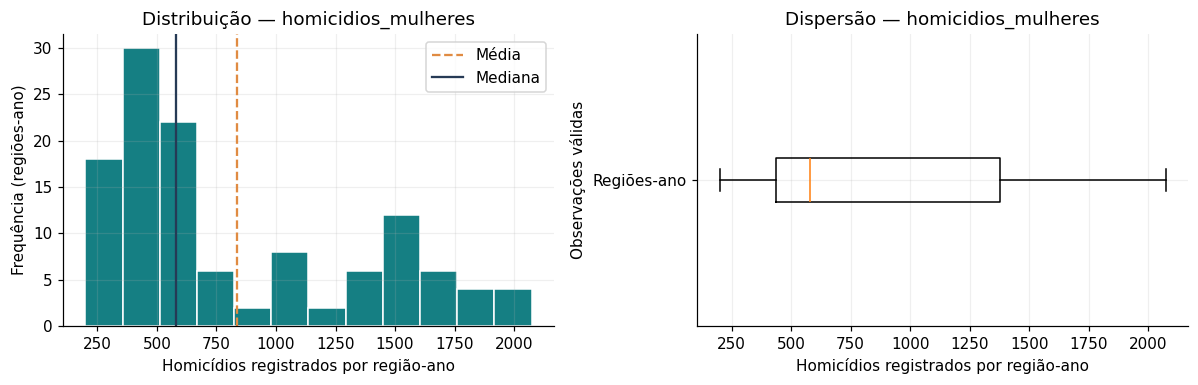

**Leitura:** Em 120 observações válidas, média = 836.79, mediana = 578.50, desvio-padrão = 528.46 e assimetria = 0.81. Os extremos permanecem na análise.

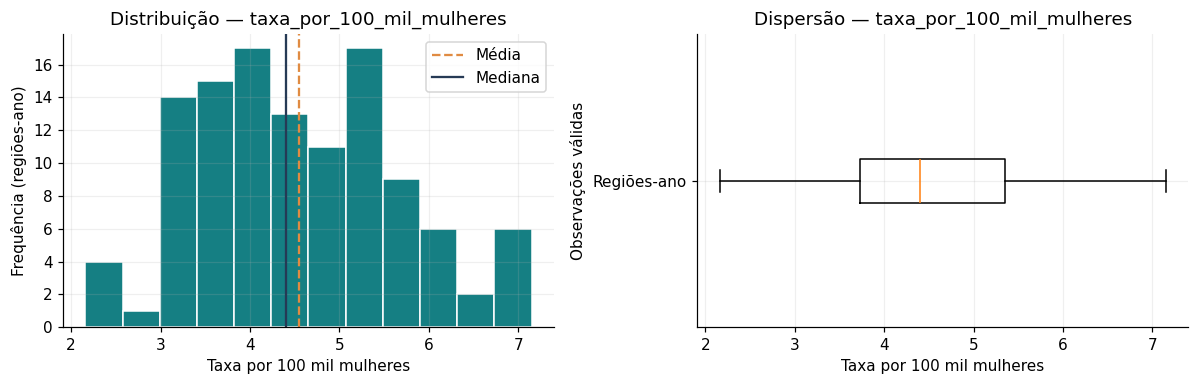

**Leitura:** Em 115 observações válidas, média = 4.55, mediana = 4.40, desvio-padrão = 1.14 e assimetria = 0.23. Os extremos permanecem na análise.

In [10]:
def resumo_num(s):
    s=s.dropna(); q1,q3=s.quantile([.25,.75]); modas=s.mode()
    return {'n':len(s),'ausentes':len(df)-len(s),'média':s.mean(),'mediana':s.median(),
            'moda(s)': ', '.join(map(str,modas.tolist())) if len(modas)<len(s) else 'sem moda única: todos distintos',
            'desvio-padrão amostral':s.std(ddof=1),'variância amostral':s.var(ddof=1),
            'CV (%)':100*s.std(ddof=1)/s.mean() if s.mean()!=0 else np.nan,
            'mínimo':s.min(),'Q1':q1,'Q3':q3,'máximo':s.max(),'amplitude':s.max()-s.min(),
            'IQR':q3-q1,'assimetria amostral':s.skew(),'curtose excedente amostral':s.kurt()}
estatisticas=pd.DataFrame({c:resumo_num(df.loc[~df[c+'_imputado'],c]) for c in NUM}).T
display(estatisticas.round(3))
for c,unidade in [(NUM[0],'Homicídios registrados por região-ano'),(NUM[1],'Taxa por 100 mil mulheres')]:
    s=df[c].dropna()
    fig,ax=plt.subplots(1,2,figsize=(11,3.6))
    ax[0].hist(s,bins=12,color=COR,edgecolor='white')
    ax[0].axvline(s.mean(),color=COR2,linestyle='--',label='Média')
    ax[0].axvline(s.median(),color='#263A55',label='Mediana')
    ax[0].set(title='Distribuição — '+c,xlabel=unidade,ylabel='Frequência (regiões-ano)');ax[0].legend()
    ax[1].boxplot(s,vert=False)
    ax[1].set(title='Dispersão — '+c,xlabel=unidade,ylabel='Observações válidas');ax[1].set_yticks([1],['Regiões-ano'])
    grafico('distribuicao_'+c,f'Em {len(s)} observações válidas, média = {s.mean():.2f}, mediana = {s.median():.2f}, '
            f'desvio-padrão = {s.std():.2f} e assimetria = {s.skew():.2f}. Os extremos permanecem na análise.')


### 5.2 Frequências das regiões
A tabela mostra frequência absoluta, relativa e acumulada. O acumulado segue a ordem alfabética e não representa uma ordem natural entre regiões. São frequências de linhas região-ano, não de vítimas.


regiao | moda(s): ['Centro-Oeste', 'Nordeste', 'Norte', 'Sudeste', 'Sul']


,variável,categoria,absoluta,relativa (%),absoluta acumulada,relativa acumulada (%)
0,regiao,Centro-Oeste,24,20.0,24,20.0
1,regiao,Nordeste,24,20.0,48,40.0
2,regiao,Norte,24,20.0,72,60.0
3,regiao,Sudeste,24,20.0,96,80.0
4,regiao,Sul,24,20.0,120,100.0


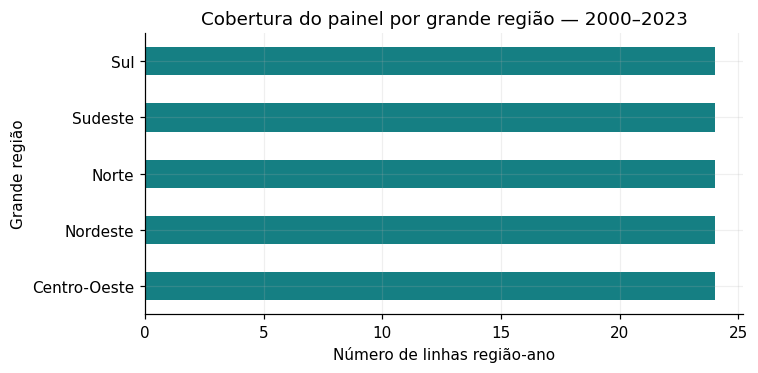

**Leitura:** Cada região tem 24 linhas (20% do painel). O equilíbrio é da grade temporal, não da quantidade de homicídios.

In [11]:
CAT = ['regiao']
frequencias = []
for c in CAT:
    f=df[c].value_counts(dropna=False).sort_index()
    t=pd.DataFrame({'categoria':f.index.astype(str),'absoluta':f.values,'relativa (%)':f.values/f.sum()*100})
    t['absoluta acumulada']=t['absoluta'].cumsum()
    t['relativa acumulada (%)']=t['absoluta acumulada']/f.sum()*100
    t.insert(0,'variável',c)
    frequencias.append(t)
    print(c, '| moda(s):', df[c].mode().tolist())
frequencias=pd.concat(frequencias,ignore_index=True)
display(frequencias.round(3))
fig,ax=plt.subplots(figsize=(7,3.5))
df['regiao'].value_counts().sort_index().plot.barh(ax=ax,color=COR)
ax.set(title='Cobertura do painel por grande região — 2000–2023',xlabel='Número de linhas região-ano',ylabel='Grande região')
grafico('cobertura_regional','Cada região tem 24 linhas (20% do painel). O equilíbrio é da grade temporal, não da quantidade de homicídios.')


### 5.3 Série temporal
Somamos as contagens regionais para obter o total nacional. A taxa Brasil vem da série nacional da fonte. Como os dados são anuais, não analisamos sazonalidade mensal.


,homicidios_Brasil,variação anual (%)
ano,,
2000,3744,NaN
2001,3851,2.858
2002,3868,0.441
2003,3941,1.887
2004,3831,-2.791
2005,3887,1.462
2006,4030,3.679
2007,3778,-6.253
2008,4029,6.644


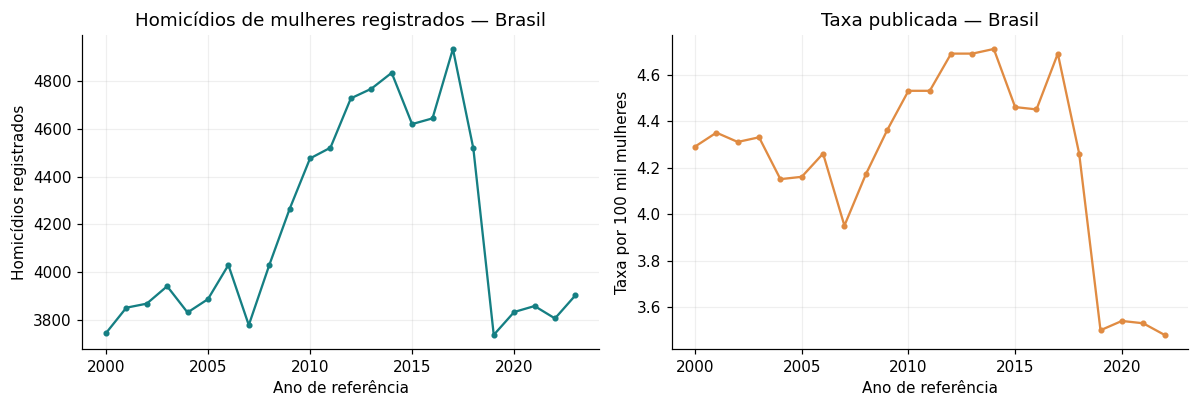

**Leitura:** O total registrado passa de 3,744 em 2000 para 3,903 em 2023; o pico é 4,936 em 2017. A taxa nacional disponível termina em 2022, e não foi extrapolada.

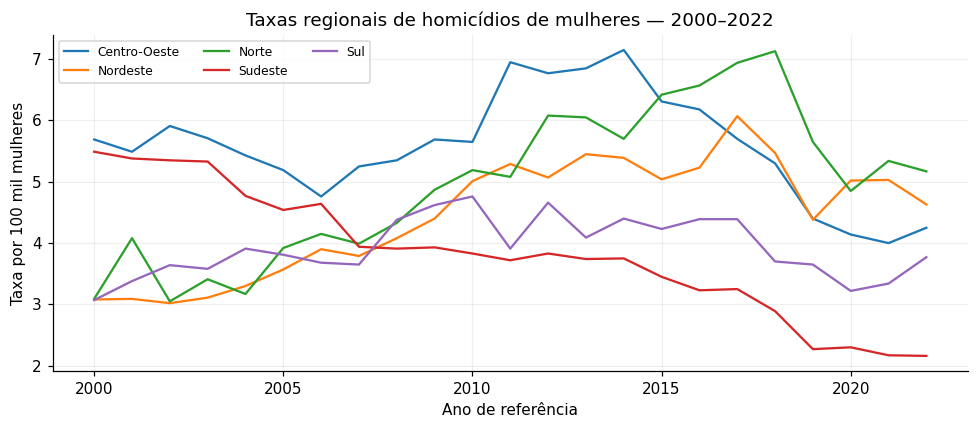

**Leitura:** Em 2022, a maior taxa regional é de 5.17 no Norte, e a menor é de 2.16 no Sudeste. Variações podem refletir mudanças na violência registrada, na população e na qualidade dos registros.

In [12]:
anual = df.groupby('ano')['homicidios_mulheres'].sum(min_count=5).to_frame('homicidios_Brasil')
anual['variação anual (%)']=anual['homicidios_Brasil'].pct_change(fill_method=None)*100
display(anual.round(3))
bn = taxa_nacional.assign(ano=pd.to_datetime(taxa_nacional.periodo,utc=True).dt.year)
bn=bn.loc[bn.ano.between(ANO_INICIO,ANO_FIM)].set_index('ano')['valor']
fig,ax=plt.subplots(1,2,figsize=(11,3.8))
ax[0].plot(anual.index,anual.homicidios_Brasil,color=COR,marker='o',markersize=3)
ax[0].set(title='Homicídios de mulheres registrados — Brasil',xlabel='Ano de referência',ylabel='Homicídios registrados')
ax[1].plot(bn.index,bn.values,color=COR2,marker='o',markersize=3)
ax[1].set(title='Taxa publicada — Brasil',xlabel='Ano de referência',ylabel='Taxa por 100 mil mulheres')
grafico('serie_temporal_brasil',f'O total registrado passa de {anual.iloc[0,0]:,.0f} em {anual.index.min()} para '
        f'{anual.iloc[-1,0]:,.0f} em {anual.index.max()}; o pico é {anual.homicidios_Brasil.max():,.0f} em '
        f'{anual.homicidios_Brasil.idxmax()}. A taxa nacional disponível termina em {bn.index.max()}, e não foi extrapolada.')

fig,ax=plt.subplots(figsize=(9,4))
for reg,t in df.groupby('regiao'):
    ax.plot(t.ano,t.taxa_por_100_mil_mulheres,label=reg)
ax.set(title='Taxas regionais de homicídios de mulheres — 2000–2022',xlabel='Ano de referência',ylabel='Taxa por 100 mil mulheres')
ax.legend(ncol=3,fontsize=8)
ultimo_taxa=int(df.loc[df[NUM[1]].notna(),'ano'].max())
recente=df.loc[df.ano.eq(ultimo_taxa)].sort_values(NUM[1],ascending=False)
grafico('taxas_regionais_tempo',f'Em {ultimo_taxa}, a maior taxa regional é de {recente.iloc[0][NUM[1]]:.2f} '
        f'no {recente.iloc[0].regiao}, e a menor é de {recente.iloc[-1][NUM[1]]:.2f} no {recente.iloc[-1].regiao}. '
        'Variações podem refletir mudanças na violência registrada, na população e na qualidade dos registros.')


### 5.4 Relações entre variáveis
Comparamos as taxas por região e a relação entre contagem e taxa. As duas medidas compartilham numerador, e as populações regionais são diferentes. A correlação não demonstra causalidade.


,n,contagem_média,contagem_mediana,taxa_média,taxa_mediana,taxa_desvio
regiao,,,,,,
Centro-Oeste,23,402.391,364.0,5.570,5.65,0.886
Nordeste,23,1245.696,1377.0,4.453,4.63,0.933
Norte,23,408.391,413.0,4.967,5.08,1.238
Sudeste,23,1579.696,1605.0,3.820,3.83,1.041
Sul,23,560.000,559.0,3.923,3.81,0.480


,homicidios_mulheres,taxa_por_100_mil_mulheres
homicidios_mulheres,1.000,-0.071
taxa_por_100_mil_mulheres,-0.071,1.000


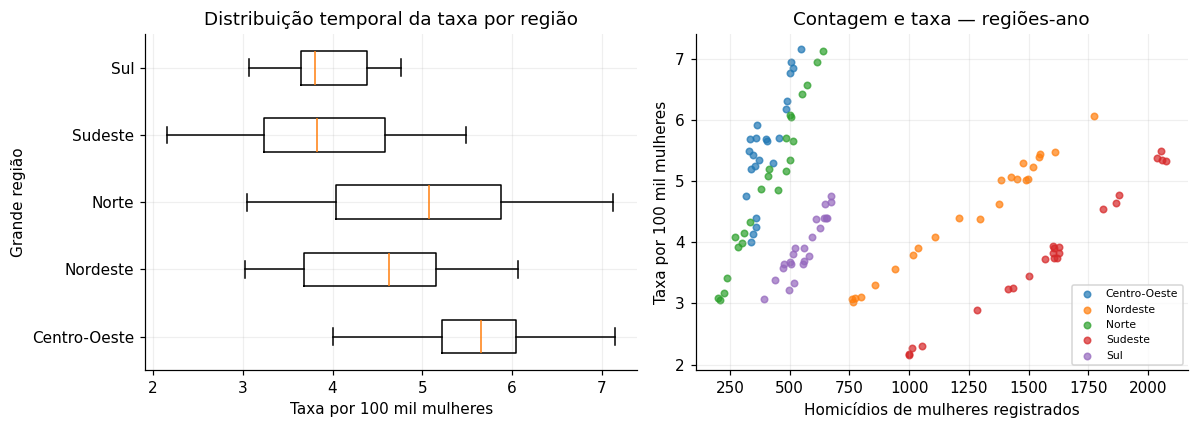

**Leitura:** Nos 115 pares completos, Spearman = -0.071. A relação mistura anos e regiões com populações distintas, e as medidas compartilham numerador; ela não demonstra causa nem risco individual.

In [13]:
comum=df.dropna(subset=NUM)
display(comum.groupby('regiao').agg(
    n=('ano','size'),contagem_média=('homicidios_mulheres','mean'),
    contagem_mediana=('homicidios_mulheres','median'),
    taxa_média=('taxa_por_100_mil_mulheres','mean'),
    taxa_mediana=('taxa_por_100_mil_mulheres','median'),
    taxa_desvio=('taxa_por_100_mil_mulheres','std')).round(3))
rho=comum[NUM[0]].rank().corr(comum[NUM[1]].rank())
display(pd.DataFrame([[1,rho],[rho,1]],index=NUM,columns=NUM).round(3))
grupos=sorted(comum.regiao.unique())
fig,ax=plt.subplots(1,2,figsize=(11,4))
ax[0].boxplot([comum.loc[comum.regiao.eq(r),NUM[1]] for r in grupos],vert=False)
ax[0].set_yticks(range(1,len(grupos)+1),grupos)
ax[0].set(title='Distribuição temporal da taxa por região',xlabel='Taxa por 100 mil mulheres',ylabel='Grande região')
for r,t in comum.groupby('regiao'):
    ax[1].scatter(t[NUM[0]],t[NUM[1]],label=r,s=18,alpha=.7)
ax[1].set(title='Contagem e taxa — regiões-ano',xlabel='Homicídios de mulheres registrados',ylabel='Taxa por 100 mil mulheres')
ax[1].legend(fontsize=7)
grafico('relacoes',f'Nos {len(comum)} pares completos, Spearman = {rho:.3f}. A relação mistura anos e regiões '
        'com populações distintas, e as medidas compartilham numerador; ela não demonstra causa nem risco individual.')


### 5.5 Três perguntas respondidas
As respostas abaixo são calculadas a partir da base tratada.


In [14]:
ano_ultimo=int(df.ano.max())
ult=df.loc[df.ano.eq(ano_ultimo)].sort_values(NUM[0],ascending=False)
lider=ult.iloc[0]; total=ult[NUM[0]].sum()
total_ini=anual.iloc[0,0];total_fim=anual.iloc[-1,0]
dif=total_fim-total_ini;pct=(total_fim/total_ini-1)*100
maior=recente.iloc[0];menor=recente.iloc[-1]
respostas = [
    ('1. Como o total registrado mudou entre 2000 e 2023?',
     f'Passou de {total_ini:.0f} para {total_fim:.0f}: diferença de {dif:+.0f} registros ({pct:+.2f}%). '
     'A mudança descreve registros, não a prevalência total de violência.'),
    (f'2. Qual região concentrou mais registros em {ano_ultimo}?',
     f'{lider.regiao}: {lider[NUM[0]]:.0f} de {total:.0f} registros ({100*lider[NUM[0]]/total:.2f}%). '
     'Maior contagem não implica maior taxa, porque as populações diferem.'),
    (f'3. Qual foi a diferença entre a maior e a menor taxa regional em {ultimo_taxa}?',
     f'{maior.regiao}: {maior[NUM[1]]:.2f}; {menor.regiao}: {menor[NUM[1]]:.2f} por 100 mil mulheres. '
     f'Diferença de {maior[NUM[1]]-menor[NUM[1]]:.2f} por 100 mil e razão de {maior[NUM[1]]/menor[NUM[1]]:.2f} vezes. '
     'Comparação ecológica descritiva, sem interpretação individual ou causal.'),
]
for pergunta,resposta in respostas:
    display(Markdown('**'+pergunta+'**  \n'+resposta))
display(pd.DataFrame(respostas,columns=['pergunta','resposta']))
display(ult[['regiao','ano']+NUM].assign(participacao_pct=ult[NUM[0]]/total*100).round(3))


**1. Como o total registrado mudou entre 2000 e 2023?**  
Passou de 3744 para 3903: diferença de +159 registros (+4.25%). A mudança descreve registros, não a prevalência total de violência.

**2. Qual região concentrou mais registros em 2023?**  
Nordeste: 1464 de 3903 registros (37.51%). Maior contagem não implica maior taxa, porque as populações diferem.

**3. Qual foi a diferença entre a maior e a menor taxa regional em 2022?**  
Norte: 5.17; Sudeste: 2.16 por 100 mil mulheres. Diferença de 3.01 por 100 mil e razão de 2.39 vezes. Comparação ecológica descritiva, sem interpretação individual ou causal.

,pergunta,resposta
0,1. Como o total registrado mudou entre 2000 e ...,Passou de 3744 para 3903: diferença de +159 re...
1,2. Qual região concentrou mais registros em 2023?,Nordeste: 1464 de 3903 registros (37.51%). Mai...
2,3. Qual foi a diferença entre a maior e a meno...,Norte: 5.17; Sudeste: 2.16 por 100 mil mulhere...


,regiao,ano,homicidios_mulheres,taxa_por_100_mil_mulheres,participacao_pct
47,Nordeste,2023,1464,NaN,37.510
71,Sudeste,2023,1102,NaN,28.235
95,Sul,2023,559,NaN,14.322
23,Norte,2023,462,NaN,11.837
119,Centro-Oeste,2023,316,NaN,8.096


## 6. Plano de modelagem e avaliação
**Responsável Luiz Henrique** 

| Item | Plano para a próxima entrega |
|---|---|
| Objetivo | Estudar a previsão da contagem regional de homicídios de mulheres no ano seguinte |
| Variável-alvo | Quantidade registrada no ano seguinte, por região |
| Entradas candidatas | Região e contagens dos anos anteriores |
| Técnicas | Referência que repete o valor do ano anterior e regressão regularizada simples |
| Métricas | MAE e RMSE, comparando também os resultados por região |
| Validação | Reservar os anos finais para teste; validar respeitando a ordem temporal, sem embaralhar anos |
| Cuidados | Transformações ajustadas somente no treino; não usar valores futuros; poucos anos e mudanças na qualidade dos registros podem limitar o resultado |

Nenhum modelo foi treinado e nenhuma métrica preditiva foi calculada nesta entrega. O objetivo é agregado, não uma previsão de risco individual. Se o projeto exigir classificação individual, será necessário discutir outro recorte e um alvo realmente observado com o professor.


## 7. Conclusões e conferência
**Responsáveis propostos: Bruno Henrique e Luiz Henrique — confirmar após revisão.**

A base tratada tem 120 linhas. Foram mantidas cinco taxas ausentes, todas de 2023. As análises com contagem e taxa juntas usam 115 pares completos. Os gráficos e as três respostas mostram tendências e diferenças regionais dos registros, sem demonstrar causalidade.

As limitações principais são sub-registro, possíveis revisões e a falta de detalhes dentro das regiões. Os dados não permitem concluir o risco de uma pessoa ou explicar as causas das variações.

Antes de enviar, os integrantes devem revisar e confirmar as responsabilidades, conferir o aceite do recorte e esclarecer a licença específica da API para redistribuição. A fonte é uma das sugeridas pelo enunciado, mas não alegamos aprovação formal já obtida.

Repositório, commits individuais, Kanban e envio ao AVA continuam pendentes. O arquivo `USO_IA.md` acompanha este pacote. O histórico de trabalho não pode ser criado retroativamente.


In [15]:
assert len(df)==120
assert not df.duplicated(['regiao_id','ano']).any()
assert df.groupby('ano').size().eq(5).all()
assert df[NUM[0]].notna().all()
assert df[NUM[1]].isna().sum()==5
assert df.loc[df[NUM[1]].isna(),'ano'].eq(2023).all()
assert not df[[c+'_imputado' for c in NUM]].any().any()
assert df[NUM].stack().dropna().ge(0).all()
assert len(comum)==115
assert conf.loc[ANO_INICIO:ANO_FIM,'diferença'].eq(0).all()
salvo=pd.read_csv(DADOS/'base_tratada.csv', sep=';', decimal=',')
assert len(salvo)==len(df) and set(salvo.columns)==set(colunas_csv)
assert salvo[NUM].isna().sum().equals(df[NUM].isna().sum())
for m in manifesto:
    assert hashlib.sha256((BRUTOS/m['arquivo']).read_bytes()).hexdigest()==m['sha256']
print('Verificações concluídas: 120 linhas, 115 pares completos, 5 taxas ausentes preservadas,')
print('chaves únicas, soma regional igual à série nacional e arquivos brutos intactos.')


Verificações concluídas: 120 linhas, 115 pares completos, 5 taxas ausentes preservadas,
chaves únicas, soma regional igual à série nacional e arquivos brutos intactos.
